# Simple linear regression in R

In this notebook we fit a simple linear regression that predicts **Salary** from **YearsExperience**, using only base R. The steps are:

1. Load the data
2. Clean the data and visualize it
3. Fit the regression with `lm()`
4. Add the fitted line to the plot
5. Use the model to make a prediction

----

## Load the data

Read `Salary_dataset.csv` into a data frame with `read.csv()`. The file must be in the notebook's working directory. Then look at the first few rows with `head()`.

In [1]:
# load-data
# first read the data into a data frame
df <- read.csv("Salary_dataset.csv")

# look at the first few rows
head(df)

  X YearsExperience Salary
1 0             1.2  39344
2 1             1.4  46206
3 2             1.6  37732
4 3             2.1  43526
5 4             2.3  39892
6 5             3.0  56643

## Clean the data

The first column, `X`, is just a row number left over from how the file was saved (its header was blank, so R named it `X`). We drop it with `subset()` and then print the head again to confirm it is gone.

In [2]:
# drop-index-column
# the first column X is just the row
# number, so we can omit it.
df <- subset(df, select = -X)

# confirm that we removed X
head(df)

  YearsExperience Salary
1             1.2  39344
2             1.4  46206
3             1.6  37732
4             2.1  43526
5             2.3  39892
6             3.0  56643

## Visualize the data

Before fitting a model, plot Salary against YearsExperience to see whether a straight line is a reasonable description of the relationship.

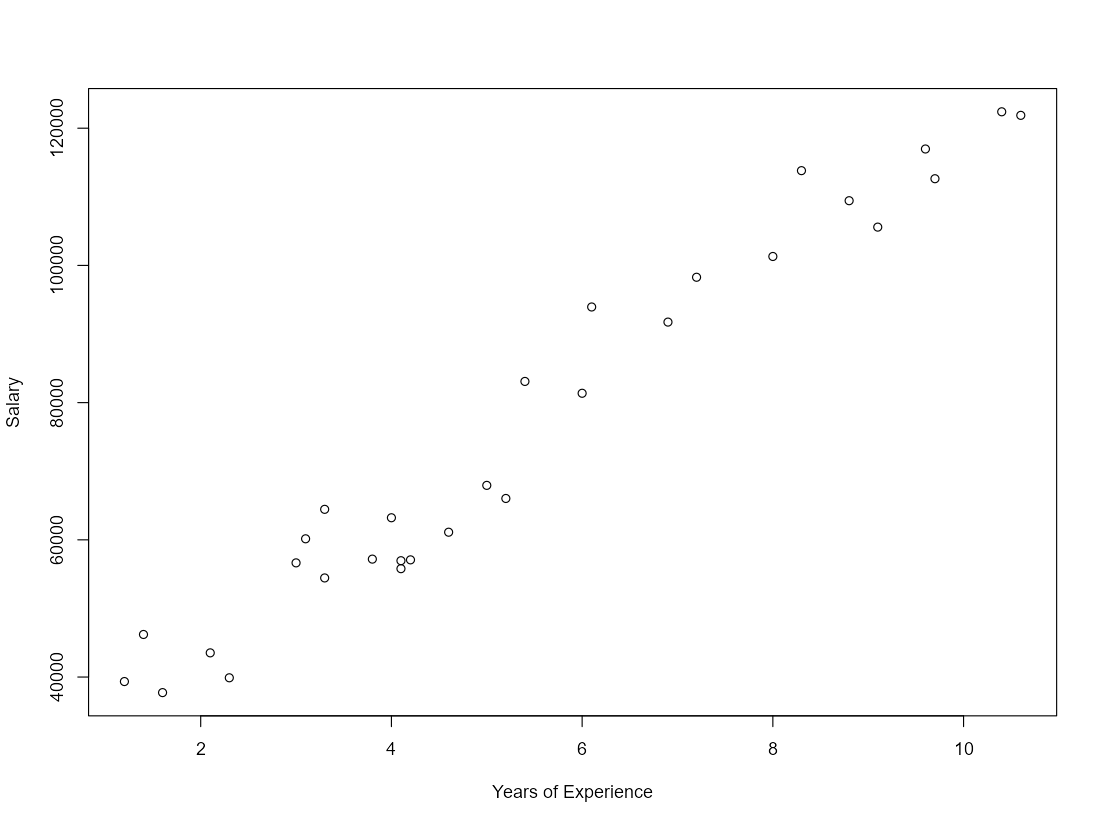

In [3]:
# plot-raw-data
# now plot the data
plot(
  df$YearsExperience,
  df$Salary,
  xlab = "Years of Experience",
  ylab = "Salary"
)

# To save a PDF of the graph with a transparent
# background, uncomment:
# pdf("salary_data_plot.pdf", width = 4, height = 4, bg = "transparent")
# plot(
#   df$YearsExperience,
#   df$Salary,
#   xlab = "Years of Experience",
#   ylab = "Salary"
# )
# dev.off()

## Fit the linear regression

`lm(Salary ~ YearsExperience, data = df)` fits an ordinary least squares model with Salary as the response and YearsExperience as the predictor. An intercept is included automatically. `summary()` reports the coefficients, standard errors, p-values, R-squared, and other diagnostics.

In [4]:
# fit-model
# now do linear regression with the data
model <- lm(Salary ~ YearsExperience, data = df)
summary(model)


Call:
lm(formula = Salary ~ YearsExperience, data = df)

Residuals:
    Min      1Q  Median      3Q     Max 
-7958.0 -4088.5  -459.9  3372.6 11448.0 

Coefficients:
                Estimate Std. Error t value
(Intercept)      24848.2     2306.7   10.77
YearsExperience   9450.0      378.8   24.95
                Pr(>|t|)    
(Intercept)     1.82e-11 ***
YearsExperience  < 2e-16 ***
---
Signif. codes:  
0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5788 on 28 degrees of freedom
Multiple R-squared:  0.957,	Adjusted R-squared:  0.9554 
F-statistic: 622.5 on 1 and 28 DF,  p-value: < 2.2e-16


## Plot the fitted line

Redraw the scatter plot, then use `abline()` with the fitted model to overlay the regression line in red.

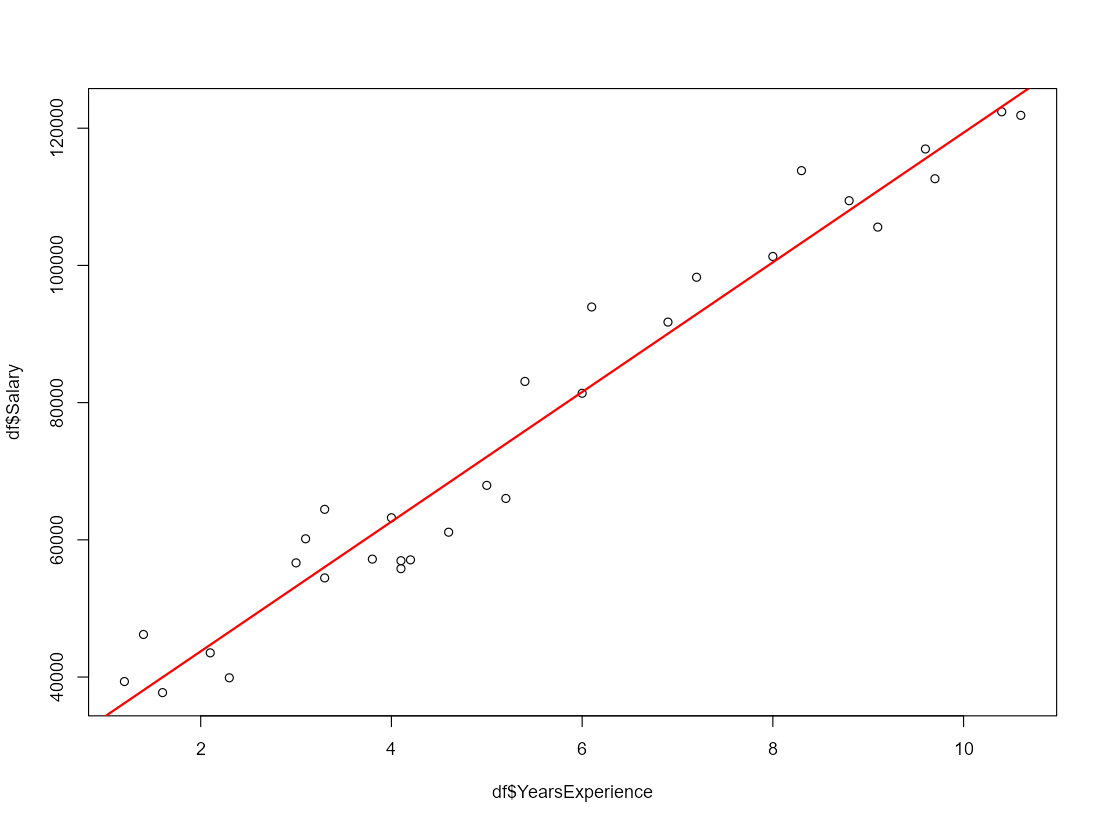

In [5]:
# plot-fitted-line
# now add the regression line to our graph
plot(df$YearsExperience, df$Salary)
abline(model, col = "red", lwd = 2)

# To save a PDF of the graph with a transparent
# background, uncomment:
# pdf("linear_regression.pdf", width = 4, height = 4, bg = "transparent")
# plot(
#   df$YearsExperience,
#   df$Salary,
#   xlab = "Years of Experience",
#   ylab = "Salary"
# )
# abline(model, col = "red", lwd = 2)
# dev.off()

## Make a prediction

A linear model should only be used to predict within (or very near) the range of the data it was fit on. So first we summarize the range of `YearsExperience`.

In [6]:
# summarize-input-range
# now summarize the range of YearsExperience
# that are reasonable input values for
# our model
summary(df$YearsExperience)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.200   3.300   4.800   5.413   7.800  10.600 

Now predict the salary for someone with 6.3 years of experience. `predict()` needs a new data frame whose column name matches the predictor in the model formula.

In [7]:
# predict-salary
# now predict the salary for someone
# with 6.3 years of experience
predict(model, newdata = data.frame(YearsExperience = 6.3))

       1 
84382.97 